# **1.SQLite**

SQLite는 별도의 데이터베이스 서버를 설치하지 않고 파일로 사용하는 데이터베이스

In [1]:
import sqlite3
from pathlib import Path

In [2]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
simple_path = DATA_DIR / "hello.db"

In [3]:
conn_simple = sqlite3.connect(simple_path)
print("연결 성공:", simple_path.resolve())

연결 성공: C:\SHJ\KDT\14_Agent\data\hello.db


In [4]:
conn_simple.execute("""
CREATE TABLE students(
    id INTEGER PRIMARY KEY,
    name VARCHAR(20) NOT NULL,
    score INTEGER NOT NULL
)
""")

OperationalError: table students already exists

In [7]:
students = [(1, "김사과", 90), (2, "반하나", 85), (3, "오렌지", 95)]
conn_simple.executemany("INSERT INTO students (id, name, score) VALUES (?, ?, ?)", students)
conn_simple.commit()
print("학생 데이터 저장 완료")

IntegrityError: UNIQUE constraint failed: students.id

In [ ]:
rows = conn_simple.execute("SELECT name, score FROM students WHERE score >= ? ORDER BY score DESC", (90,)).fetchall()

for name, score in rows:
    print(name, score)

오렌지 95
김사과 90


In [8]:
import pandas as pd

In [9]:
pd.read_sql_query("SELECT * FROM students ORDER BY score DESC", conn_simple)

,id,name,score
0,3,오렌지,95
1,1,김사과,90
2,2,반하나,85


In [10]:
conn_simple.close()
print("연습용 DB 연결 종료")

연습용 DB 연결 종료


In [11]:
import requests

In [12]:
path = DATA_DIR / "Chinook.db"
if not path.exists():
    url = "https://storage.googleapis.com/benchmarks-artifacts/chinook/Chinook.db"
    response = requests.get(url, timeout=30)
    path.write_bytes(response.content)

print("DB 파일:", path.resolve())
conn = sqlite3.connect(path)
print("연결 성공!")

DB 파일: C:\SHJ\KDT\14_Agent\data\Chinook.db
연결 성공!


In [13]:
tables = conn.execute("SELECT name FROM sqlite_master WHERE TYPE='table' ORDER BY name").fetchall()
print([name for (name,) in tables])

['Album', 'Artist', 'Customer', 'Employee', 'Genre', 'Invoice', 'InvoiceLine', 'MediaType', 'Playlist', 'PlaylistTrack', 'Track']


In [14]:
pd.read_sql_query("SELECT * FROM customer LIMIT 5", conn)

,CustomerId,FirstName,LastName,Company,Address,City,State,Country,PostalCode,Phone,Fax,Email,SupportRepId
0,1,Luís,Gonçalves,Embraer - Empresa Brasileira de Aeronáutica S.A.,"Av. Brigadeiro Faria Lima, 2170",São José dos Campos,SP,Brazil,12227-000,+55 (12) 3923-5555,+55 (12) 3923-5566,luisg@embraer.com.br,3
1,2,Leonie,Köhler,NaN,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,+49 0711 2842222,NaN,leonekohler@surfeu.de,5
2,3,François,Tremblay,NaN,1498 rue Bélanger,Montréal,QC,Canada,H2G 1A7,+1 (514) 721-4711,NaN,ftremblay@gmail.com,3
3,4,Bjørn,Hansen,NaN,Ullevålsveien 14,Oslo,NaN,Norway,0171,+47 22 44 22 22,NaN,bjorn.hansen@yahoo.no,4
4,5,František,Wichterlová,JetBrains s.r.o.,Klanova 9/506,Prague,NaN,Czech Republic,14700,+420 2 4172 5555,+420 2 4172 5555,frantisekw@jetbrains.com,4


In [15]:
pd.read_sql_query("SELECT * FROM invoice LIMIT 5", conn)

,InvoiceId,CustomerId,InvoiceDate,BillingAddress,BillingCity,BillingState,BillingCountry,BillingPostalCode,Total
0,1,2,2009-01-01 00:00:00,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,1.98
1,2,4,2009-01-02 00:00:00,Ullevålsveien 14,Oslo,NaN,Norway,0171,3.96
2,3,8,2009-01-03 00:00:00,Grétrystraat 63,Brussels,NaN,Belgium,1000,5.94
3,4,14,2009-01-06 00:00:00,8210 111 ST NW,Edmonton,AB,Canada,T6G 2C7,8.91
4,5,23,2009-01-11 00:00:00,69 Salem Street,Boston,MA,USA,2113,13.86


In [16]:
# 주문별 고객 이름과 주문 금액(customer, invoice)
pd.read_sql_query("""
    SELECT c.firstname, c.lastname, i.total FROM customer AS c JOIN invoice AS i
    ON c.customerid = i.customerid LIMIT 10
""", conn)

,FirstName,LastName,Total
0,Leonie,Köhler,1.98
1,Bjørn,Hansen,3.96
2,Daan,Peeters,5.94
3,Mark,Philips,8.91
4,John,Gordon,13.86
5,Fynn,Zimmermann,0.99
6,Niklas,Schröder,1.98
7,Dominique,Lefebvre,1.98
8,Wyatt,Girard,3.96
9,Hugh,O'Reilly,5.94


In [17]:
# 국가별 주문 총액 상위 5개
pd.read_sql_query("""
SELECT billingcountry, ROUND(SUM(total), 2) AS revenue 
FROM invoice 
GROUP BY billingcountry
ORDER BY revenue 
DESC
LIMIT 5
""", conn)

,BillingCountry,revenue
0,USA,523.06
1,Canada,303.96
2,France,195.10
3,Brazil,190.10
4,Germany,156.48


# **2. LangChain으로 연결**

In [18]:
from langchain_community.utilities import SQLDatabase

In [19]:
# as_posix: 경로 구분자를 / 형태로 변환
db = SQLDatabase.from_uri(f"sqlite:///{path.resolve().as_posix()}")
print("DB 종류:", db.dialect)
print("테이블:", db.get_usable_table_names())
print("\nInvoice 테이블 구조 일부:")
print(db.get_table_info(["Invoice"])[:1200])

DB 종류: sqlite
테이블: ['Album', 'Artist', 'Customer', 'Employee', 'Genre', 'Invoice', 'InvoiceLine', 'MediaType', 'Playlist', 'PlaylistTrack', 'Track']

Invoice 테이블 구조 일부:

CREATE TABLE "Invoice" (
	"InvoiceId" INTEGER NOT NULL, 
	"CustomerId" INTEGER NOT NULL, 
	"InvoiceDate" DATETIME NOT NULL, 
	"BillingAddress" NVARCHAR(70), 
	"BillingCity" NVARCHAR(40), 
	"BillingState" NVARCHAR(40), 
	"BillingCountry" NVARCHAR(40), 
	"BillingPostalCode" NVARCHAR(10), 
	"Total" NUMERIC(10, 2) NOT NULL, 
	PRIMARY KEY ("InvoiceId"), 
	FOREIGN KEY("CustomerId") REFERENCES "Customer" ("CustomerId")
)

/*
3 rows from Invoice table:
InvoiceId	CustomerId	InvoiceDate	BillingAddress	BillingCity	BillingState	BillingCountry	BillingPostalCode	Total
1	2	2009-01-01 00:00:00	Theodor-Heuss-Straße 34	Stuttgart	None	Germany	70174	1.98
2	4	2009-01-02 00:00:00	Ullevålsveien 14	Oslo	None	Norway	0171	3.96
3	8	2009-01-03 00:00:00	Grétrystraat 63	Brussels	None	Belgium	1000	5.94
*/


In [20]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

In [21]:
load_dotenv()

True

In [22]:
MODEL = os.getenv("OPEN_MODEL", "gpt-5.6-luna")
llm = ChatOpenAI(model=MODEL, temperature=0)

In [23]:
from langchain_core.messages import HumanMessage

In [37]:
schema = db.get_table_info(["Invoice", "Customer", "Employee"])
question = "2009년에 고객 담당 직원별 매출 함계 상위 3명을 알려줘"
prompt = f"""
    SQLite SELECT 쿼리 하나만 작성하세요. 코드블록 없이 SQL만 출력하세요.
    스키마: {schema}
    질문: {question}
    조건: Invoice.Total의 합계를 사용하고 InvoiceDate는 2009년으로 제한합니다.
    고객의 SupportRepId를 담당 직원으로 정의합니다. 결과는 최대 3행.
    INSERT/UPDATE/DELETE/DROP 등 데이터 변경문은 절대 금지합니다.
"""

In [38]:
raw_sql = llm.invoke([HumanMessage(content=prompt)]).content
print(raw_sql)

SELECT
    e."EmployeeId",
    e."FirstName",
    e."LastName",
    SUM(i."Total") AS "TotalSales"
FROM "Invoice" AS i
JOIN "Customer" AS c
    ON i."CustomerId" = c."CustomerId"
JOIN "Employee" AS e
    ON c."SupportRepId" = e."EmployeeId"
WHERE i."InvoiceDate" >= '2009-01-01'
  AND i."InvoiceDate" < '2010-01-01'
GROUP BY e."EmployeeId", e."FirstName", e."LastName"
ORDER BY "TotalSales" DESC
LIMIT 3;


In [39]:
import re

In [48]:
def read_only_query(sql: str, max_rows=20):
    sql = re.sub(r"^```(?:sql)?\s*|\s*```$", "", sql.strip(), flags=re.I).strip()
    if not re.match(r"^(SELECT|WITH)\b", sql, flags=re.I):
        raise ValueError("SELECT 또는 WITH 형태의 단일 쿼리만 허용합니다.")
    if re.search(r"\b(INSERT|UPDATE|DELETE|DROP|ALTER|CREATE|ATTACH|DETACH|PRAGMA|REPLACE|VACUUM)\b", sql, flags=re.I):
        raise ValueError("허용되지 않는 SQL 키워드가 있습니다.")
    cur = conn.execute(sql)
    columns = [d[0] for d in cur.description]
    return pd.DataFrame(cur.fetchmany(max_rows), columns=columns)
try:
    display(read_only_query(raw_sql))
except Exception as exc:
    print(type(exc).__name__, str(exc))

,EmployeeId,FirstName,LastName,TotalSales
0,5,Steve,Johnson,164.34
1,4,Margaret,Park,161.37
2,3,Jane,Peacock,123.75


# **3. LangChain Toolkit**
SQL Toolkit은 테이블 목록, 스키마 조회, 쿼리 검사, 실행 도구 등이 있음

In [49]:
from langchain_community.agent_toolkits import SQLDatabaseToolkit

In [50]:
toolkit = SQLDatabaseToolkit(db=db, llm=llm)
for tool in toolkit.get_tools():
    print(tool.name, ": ", tool.description[:100])

sql_db_query :  Input to this tool is a detailed and correct SQL query, output is a result from the database. If the
sql_db_schema :  Input to this tool is a comma-separated list of tables, output is the schema and sample rows for tho
sql_db_list_tables :  Input is an empty string, output is a comma-separated list of tables in the database.
sql_db_query_checker :  Use this tool to double check if your query is correct before executing it. Always use this tool bef


In [51]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [52]:
schema = db.get_table_info(['Invoice', 'Customer', 'Employee'])
question = "2009년에 고객 담당 직원별 매출 합계 상위 3명을 알려줘"

In [53]:
class SQLState(TypedDict, total=False):
    question: str
    sql: str
    result: str
    answer: str
    error: str

def generate_sql(state: SQLState):
    p = f"""다음 SQLite 스키마만 사용해 SELECT SQL 하나를 만드세요.
    코드블록 없이 SQL만 출력하고 LIMIT 10을 포함하세요.
    스키마: {schema}
    질문: {state['question']}"""
    return {'sql': llm.invoke(p).content}

def execute_sql(state: SQLState):
    try:
        df = read_only_query(state['sql'], max_rows=10)
        return {"result": df.to_json(orient="records", force_ascii=False), "error": ""}
    except Exception as e:
        return {"result": "", "error": str(e)}

def make_answer(state: SQLState):
    if state.get("error"):
        return {"answer": "쿼리 실행 실패:" + state["error"]}
    msg = f"질문: {state['question']}\n조회 결과: {state['result']}\n조회 결과에 근거하여 한국어로 답하세요."
    return {"answer": llm.invoke(msg).content}

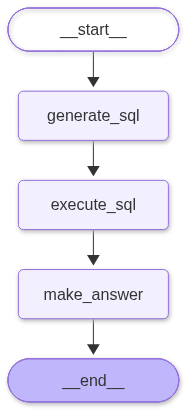

In [54]:
builder = StateGraph(SQLState)
builder.add_node("generate_sql", generate_sql)
builder.add_node("execute_sql", execute_sql)
builder.add_node("make_answer", make_answer)

builder.add_edge(START, "generate_sql")
builder.add_edge("generate_sql", "execute_sql")
builder.add_edge("execute_sql", "make_answer")
builder.add_edge("make_answer", END)

sql_graph = builder.compile()

sql_graph

In [56]:
result = sql_graph.invoke({"question": "2009년 고객 담당 직원별 매출 합계 1위는 누구인가요?"})
print("생성 SQL:", result["sql"])
print("조회 결과:", result["result"])
print("최종 답변:", result["answer"])

생성 SQL: SELECT e."FirstName" || ' ' || e."LastName" AS "EmployeeName", SUM(i."Total") AS "TotalSales"
FROM "Invoice" i
JOIN "Customer" c ON i."CustomerId" = c."CustomerId"
JOIN "Employee" e ON c."SupportRepId" = e."EmployeeId"
WHERE i."InvoiceDate" >= '2009-01-01'
  AND i."InvoiceDate" < '2010-01-01'
GROUP BY e."EmployeeId", e."FirstName", e."LastName"
ORDER BY "TotalSales" DESC
LIMIT 10;
조회 결과: [{"EmployeeName":"Steve Johnson","TotalSales":164.34},{"EmployeeName":"Margaret Park","TotalSales":161.37},{"EmployeeName":"Jane Peacock","TotalSales":123.75}]
최종 답변: 2009년 고객 담당 직원별 매출 합계 1위는 **Steve Johnson**으로, 총매출은 **164.34**입니다.


In [58]:
import gradio as gr

c:\SHJ\KDT\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [69]:
with gr.Blocks() as demo:
    with gr.Tab("1. 회의 생성"):
        gr.Markdown("# Gradio Tabs 미니 예제")
        gr.Markdown("### 본편의 탭 UI를 아주 작게 축소한 버전입니다.")

        text_input = gr.Textbox(label="제목", placeholder="주간 회의", lines=1)
        text_input = gr.Textbox(label="참가자(쉼표)", placeholder="김매니저, 이개발", lines=1)

        button = gr.Button("생성")
    with gr.Tab("2. 간단 요약"):
        text_input = gr.Textbox(label="회의록", placeholder="김: 목표공유 \n이: API 완료 예정", lines=10)

        button = gr.Button("요약")

demo.launch()

* Running on local URL:  http://127.0.0.1:7866
* To create a public link, set `share=True` in `launch()`.


In [ ]:
""